In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

In [2]:
# common graphite paramaters

graph_a = 2.46 # inplane lattice constant
graph_d = graph_a / np.sqrt(3) # nearest neighbor C-C distance
graph_c = 6.7 # height of 2 layer bernal repeat
graph_t = -2.7 # nearest neighor inplane hopping
graph_gamma1 = 0.39 # vertical hopping
del_1 = graph_d * np.array([0, 1])
del_2 = graph_d * np.array([np.sqrt(3)/2, -1/2])
del_3 = graph_d * np.array([-np.sqrt(3)/2, -1/2])

def f_k(k):
    return np.exp(1j * (k @ del_1)) + np.exp(1j * (k @ del_2)) + np.exp(1j * (k @ del_3)) 

In [3]:
########## Problem 1

# task 1

# The real space hopping sum has to do with creating and annihilating particles at different sites. If we take that H = t Sum[a_dag_R b_R+delta + b_dag_R+delta a_R] and sub in
# the momentum space operators a_R = 1/Sqrt(N) Sum[e^(i k R) a_k] and b_R+delta = 1/Sqrt(N) Sum[e^(i k' R+delta) b_k'], you get
# H = t Sum[{1/Sqrt(N) Sum[e^(-i k R) a_dag_k] 1/Sqrt(N) Sum[e^(i k' R+delta) b_k']} + {1/Sqrt(N) Sum[e^(-i k' R+delta) b_dag_k'] 1/Sqrt(N) Sum[e^(i k R) a_k]}]. For the
# exponential Sum[e^(i(k' - k) R)] = N delta_k_k' which leaves just the e^(i k delta) parts, which is the defined function f_k in the last cell. Using that function, the hamiltonian
# is then H = t Sum[f_k(k) a_dag_k b_k + f_k*(k) b_dag_k a_k]. Since we are considering nearest neighbor, the diagonal terms are 0 because they are not an A->B or B->A hopping.
# As for the other elements, destroying at a and creating at b gives tf* and destroying at b and creating at a gives tf, which results in the needed hamiltonian. 

# The orbital interactions in the off diagonal elements are from p_z at each delta location. The s, p_x, and p_y orbitals are bound in plane with only p_z sticking out. At least
# this is what I gather, but I can't say I'm confident about this part of the problem. For whatever reason, likely my browser's inbuilt vpn, chemistry stack exchange has blocked
# my ip and I can't read the rest of the post discussing p orbitals in graphite. 

In [4]:
# task 2

# The eigenvalues can be found by det(H-IE) = 0, which ends with E = +- t * abs(f_K). Using a test k of (1,1), the eigenvalues can be compared to what would be found with the
# eigvalsh function. They end up being the same. 

k_test = np.array([1,1])

H = np.array([[0, graph_t * f_k(k_test)], [graph_t * np.conj(f_k(k_test)), 0]])

E = np.linalg.eigvalsh(H)

print("Using det and test k (eV):", graph_t * np.abs(f_k(k_test)), - graph_t * np.abs(f_k(k_test)))
print("From eigvalsh (eV):", E)

Using det and test k (eV): -2.3180928081977275 2.3180928081977275
From eigvalsh (eV): [-2.31809281  2.31809281]


In [5]:
# task 3

# Since the points are given, I can just plug them in where I used test k before and print the energies. The assignment also says to make sure f(Gamma) = 3, f(K) = 0, and 
# f(M) = 1. These all line up as needed, and f(K) is only off by machine precision errors. 

Gamma_point = np.array([0, 0])
K_point = np.array([4 * np.pi /(3 * graph_a), 0])
M_point = np.array([np.pi / graph_a, np.pi / (graph_a * np.sqrt(3))])

print("|f| at Gamma:", np.abs(f_k(Gamma_point)))
print("Energies at Gamma (eV):", graph_t * np.abs(f_k(Gamma_point)), - graph_t * np.abs(f_k(Gamma_point)))
print("|f| at K:", np.abs(f_k(K_point)))
print("Energies at K (eV):", graph_t * np.abs(f_k(K_point)), - graph_t * np.abs(f_k(K_point)))
print("|f| at M:", np.abs(f_k(M_point)))
print("Energies at M (eV):", graph_t * np.abs(f_k(M_point)), - graph_t * np.abs(f_k(M_point)))

|f| at Gamma: 3.0
Energies at Gamma (eV): -8.100000000000001 8.100000000000001
|f| at K: 4.440892098500626e-16
Energies at K (eV): -1.1990408665951691e-15 1.1990408665951691e-15
|f| at M: 1.0
Energies at M (eV): -2.7 2.7


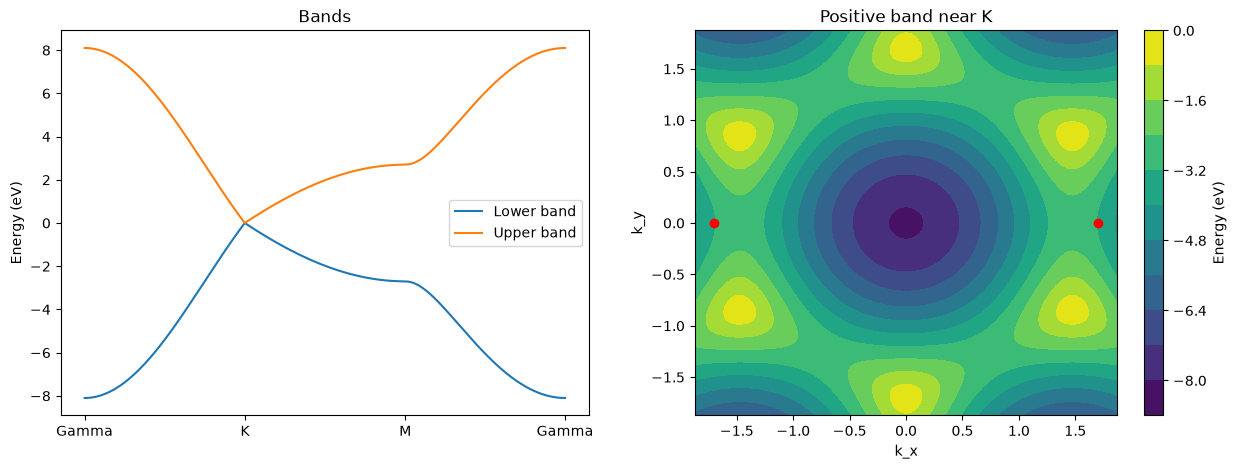

In [6]:
# task 4

# For the first graph, I just make a linspace from G to K, K to M, and M to G, and combine them into one long path. Then I calculate the energy along each point and graph
# the bands. For the second graph, I make a linspace from a bit more than -K to K and turn that into a plane. I calculate the energy at each point and plot those as well.
# The dirac points are in red. 

GK = np.linspace(Gamma_point, K_point, 1000)
KM = np.linspace(K_point, M_point, 1000)
MG = np.linspace(M_point, Gamma_point, 1000)

path = np.vstack([GK, KM[1:], MG[1:]])

E_low = []
E_high = []

for i in range(len(path)):
    E_low.append(graph_t * np.abs(f_k(path[i])))
    E_high.append(- graph_t * np.abs(f_k(path[i])))

ticks = [0, len(GK), len(GK) + len(KM), len(path)]

k_to_kprime = np.linspace(1.1 *(- 4 * np.pi /(3 * graph_a)), 1.1 * (4 * np.pi /(3 * graph_a)), 1000)
KX, KY = np.meshgrid(k_to_kprime, k_to_kprime)

E_pos = np.zeros_like(KX)

for i in range(len(k_to_kprime)):
    for j in range(len(k_to_kprime)):
        k = np.array([k_to_kprime[i], k_to_kprime[j]])
        E_pos[i, j] = graph_t * np.abs(f_k(k))

fig, axes = plt.subplots(1, 2, figsize = (15, 5))

axes[0].plot(E_low, label = "Lower band")
axes[0].plot(E_high, label = "Upper band")
axes[0].set_xticks(ticks)
axes[0].set_xticklabels(["Gamma", "K", "M", "Gamma"])
axes[0].set_ylabel("Energy (eV)")
axes[0].set_title("Bands")
axes[0].legend()

contour = axes[1].contourf(KX, KY, E_pos, levels = 10)
axes[1].scatter([K_point[0], -K_point[0]], [0, 0], color = "r", marker = "o")
axes[1].set_xlabel("k_x")
axes[1].set_ylabel("k_y")
axes[1].set_title("Positive band near K")
fig.colorbar(contour, label = "Energy (eV)")

plt.savefig("problem1_task4_graph.png", dpi = 600)

In [7]:
# task 5 

# If we let K -> K + delta_K, then e^(i K @ del) -> e^(i (K + delta_K) @ del) = e^(i K @ del) * e^(i delta_K @ del). We expand the 2nd exponential into 1 + i delta_K @ del, 
# and multiply by the first exponential. The first term is 0, since energy at the K point is 0, meaning we just consider (i delta_K @ del) * e^(i K @ del). Using the given
# del's we get that delta_K @ del_1 = d delta_K_y, delta_K @ del_2 = d(sqrt(3)/2 delta_K_x - 1/2 delta_K_y), and delta_K @ del_3 = d(- sqrt(3)/2 delta_K_x - 1/2 delta_K_y).
# We also do the same with the exponentials, finding e^0, e^(i 2pi/3), and e^(-i 2pi/3), and then get the resulting sum:
# i d {delta_K_y + e^(i 2pi/3) * (sqrt(3)/2 delta_K_x - 1/2 delta_K_y) + e^(-i 2pi/3) * (-sqrt(3)/2 delta_K_x - 1/2 delta_K_y)} = 3d/2 {i delta_K_y - delta_K_x}
# and the magnitude is then 3d/2 |delta_K|. So the energy is then 3dt/2 |delta_K|, and E = hbar * v, so hbar * v = 3dt/2 |delta_K|

hbar = 6.582119569 * 10**(-16)

v_F = 1.5 * graph_d * 10**(-10) * np.abs(graph_t) / hbar
print("Velocity in m/s:", v_F)

Velocity in m/s: 873904.0170323353


In [8]:
# task 6

# There are two bands because the only considered orbitals are p_z, and there is a bonding and antibonding band for each. Half filling just fills up the entire lower band, 
# and since at K the lower and upper band both have energy of 0, the fermi energy is where the bands touch. 

In [9]:
########## Problem 2

# task 1

# With the layered graphite, we have an additional interaction being the B1-A2 pair. The blocks for A1B1 and A2B2 will just be the hamiltonian from the last problem, so the
# full 4x4 will be two of those + the gamma_1 interaction in two places. We can verify hermiticity by just conjugating and subtracting to find that the result is 0 using the
# same test k from before. 

H_2 = np.array([[0, graph_t * f_k(k_test), 0, 0], 
                [graph_t * np.conj(f_k(k_test)), 0, graph_gamma1, 0], 
                [0, graph_gamma1, 0, graph_t * f_k(k_test)], 
                [0, 0, graph_t * np.conj(f_k(k_test)), 0]])

print(H_2 - H_2.conj().T)

print("Nonzero at:")
for i in range(4):
    if i == 0:
        x_orbit = "A1"
    if i == 1:
            x_orbit = "B1"
    if i == 2:
            x_orbit = "A2"
    if i == 3:
            x_orbit = "B2"
    for j in range(4):
        if j == 0:
                y_orbit = "A1"
        if j == 1:
                y_orbit = "B1"
        if j == 2:
                y_orbit = "A2"
        if j == 3:
                y_orbit = "B2"
        if H_2[i,j] != 0:
            print(x_orbit, y_orbit)

[[0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]
Nonzero at:
A1 B1
B1 A1
B1 A2
A2 B1
A2 B2
B2 A2


In [10]:
# task 2

# Using the same test k, I diagonalize and compare to the given equation. There is a small transformation needed to make s and lambda -1 and 1 instead of the loop's 0 and 1,
# but then the energy, s, and lambda are stored in an array together. I sort the array by the energy, and we can see that they are the same as from diagonalizing. 

E_2 = np.linalg.eigvalsh(H_2)

E_2_eq = []

for i in range(2):
    for j in range(2):
        s = 2 * i - 1
        l = 2 * j - 1
        E_2_eq.append([float(s * (np.sqrt(np.abs(graph_t * f_k(k_test))**2 + (graph_gamma1/2)**2) + l * (graph_gamma1/2))), s, l])

E_2_eq = sorted(E_2_eq, key = lambda x: x[0])

print("Using given equation, Energy (eV), s, lambda:", E_2_eq)
print("From eigvalsh (eV):", E_2)

Using given equation, Energy (eV), s, lambda: [[-2.521280135198258, -1, 1], [-2.131280135198258, -1, -1], [2.131280135198258, 1, -1], [2.521280135198258, 1, 1]]
From eigvalsh (eV): [-2.52128014 -2.13128014  2.13128014  2.52128014]


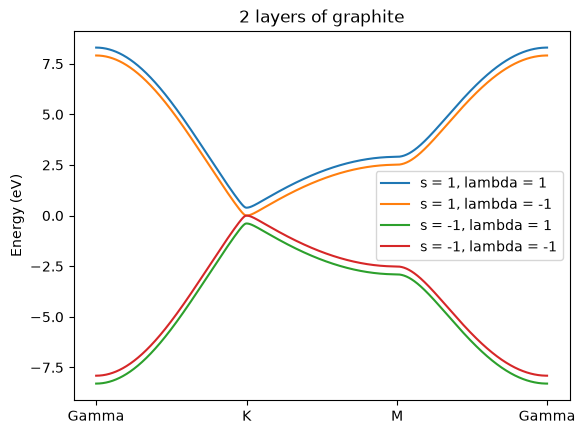

In [11]:
# task 3

# Since the Gamma, K, and M points are the same as before, we can reuse the linspace path from before. There are 4 bands, so I just iterate through the path and calculate the
# energy at each point for each band. With the layers coupled, lambda is splitting the band degeneracy. If the layers were separate, then gamma1 would be 0, and lambda would
# have no impact on the energy in general, and we would just be left with the same bands as in the previous problem just with some degeneracy. 

path = np.vstack([GK, KM[1:], MG[1:]])

band_p_p = []
band_p_m = []
band_m_p = []
band_m_m = []

for i in range(len(path)):
    band_p_p.append(float((1) * (np.sqrt(np.abs(graph_t * f_k(path[i]))**2 + (graph_gamma1/2)**2) + (1) * (graph_gamma1/2))))
    band_p_m.append(float((1) * (np.sqrt(np.abs(graph_t * f_k(path[i]))**2 + (graph_gamma1/2)**2) + (-1) * (graph_gamma1/2))))
    band_m_p.append(float((-1) * (np.sqrt(np.abs(graph_t * f_k(path[i]))**2 + (graph_gamma1/2)**2) + (1) * (graph_gamma1/2))))
    band_m_m.append(float((-1) * (np.sqrt(np.abs(graph_t * f_k(path[i]))**2 + (graph_gamma1/2)**2) + (-1) * (graph_gamma1/2))))

plt.plot(band_p_p, label = "s = 1, lambda = 1")
plt.plot(band_p_m, label = "s = 1, lambda = -1")
plt.plot(band_m_p, label = "s = -1, lambda = 1")
plt.plot(band_m_m, label = "s = -1, lambda = -1")
plt.xticks(ticks, ["Gamma", "K", "M", "Gamma"])
plt.ylabel("Energy (eV)")
plt.title("2 layers of graphite")
plt.legend()
plt.savefig("problem2_task3_graph.png", dpi = 600)

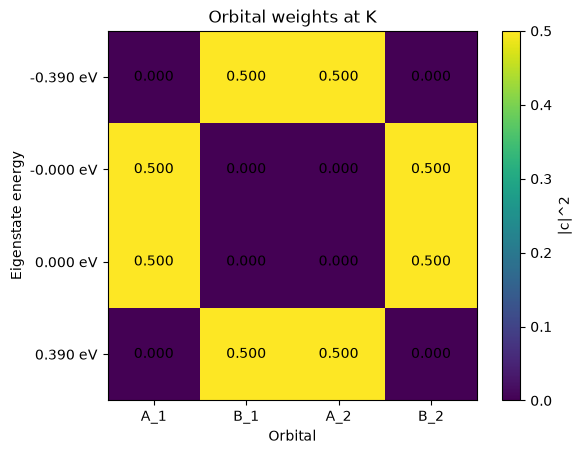

In [12]:
# task 4

# For this task, I remade the hamiltonian but with the K point instead of the test_k from before. Diagonalizing is straightforward enough, and then I find the weights at
# each site for each energy, and make a heat map. 

H_2_K = np.array([[0, graph_t * f_k(K_point), 0, 0], 
                [graph_t * np.conj(f_k(K_point)), 0, graph_gamma1, 0], 
                [0, graph_gamma1, 0, graph_t * f_k(K_point)], 
                [0, 0, graph_t * np.conj(f_k(K_point)), 0]])

E_2_K, C_2_K = np.linalg.eigh(H_2_K)

weights = np.zeros((4, 4))

for i in range(4):
    weights[i] = np.abs(C_2_K[i])**2

fig, ax = plt.subplots()
im = ax.imshow(weights)
ax.set_xticks(range(4))
ax.set_xticklabels(["A_1", "B_1", "A_2", "B_2"])
ax.set_yticks(range(4))
ax.set_yticklabels([f"{E_2_K[0]:.3f} eV", f"{E_2_K[1]:.3f} eV", f"{E_2_K[2]:.3f} eV", f"{E_2_K[3]:.3f} eV"])

ax.set_xlabel("Orbital")
ax.set_ylabel("Eigenstate energy")
ax.set_title("Orbital weights at K")

plt.colorbar(im, label = "|c|^2")

for i in range(4):
    for j in range(4):
        ax.text(i, j, f"{weights[i,j]:.3f}", ha = "center", va = "center")
plt.savefig("problem2_task4_graph.png", dpi = 600)

In [13]:
# task 5

# We can tell dimer sites by looking at the sites from the last task. At K, interlayer hopping is 0, and A1 and B2 don't couple to anything. So when energy is 0, the 
# weight is entirely in A1 and B2. The dimer states A2 and B1 are coupled with vertical hopping gamma1 being the energy between them.

In [14]:
# task 6

# The bands are determined by the orbitals in the repeat unit. For one layer we just have the 2 p_z orbitals which stick out "vertically", but when we add another 
# layer, there are 2 more from the 2nd layer. Now there are 4 p_z orbitals in the unit, so there will be 4 bands. Outside of the dimer bind, nothing about the coupling
# changes, so the hamiltonian construction keeps roughly the same form. 

In [15]:
########## Problem 3

# task 1

# The hamiltonian is the same except gamma1 is replaced by the given equation. To be able to use arbitrary k_x, k_y, and k_z, we will be splitting k into the k_z
# parts (vertical) and k_x/k_y parts (still used in f_k). I'm just going to make this all into one function so that I can pass the linspaces along later. As for 
# why the top and bottom layer can be combined into the one term, it's because they are both acting on the same site. The B1 below and B1 above are still only
# acting on the A2 in the middle. 

def g(k_z):
    return 2 * graph_gamma1 * np.cos(k_z * graph_c / 2)

def f_k_3(k_xy):
    return np.exp(1j * (k_xy @ del_1)) + np.exp(1j * (k_xy @ del_2)) + np.exp(1j * (k_xy @ del_3)) 

def H_3(k_x, k_y, k_z):
    k_xy = np.array([k_x, k_y])

    return np.array([[0, graph_t * f_k_3(k_xy), 0, 0], 
                [graph_t * np.conj(f_k_3(k_xy)), 0, g(k_z), 0], 
                [0, g(k_z), 0, graph_t * f_k_3(k_xy)], 
                [0, 0, graph_t * np.conj(f_k_3(k_xy)), 0]])



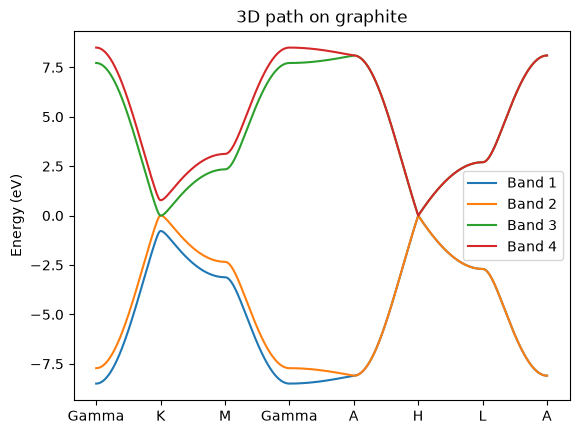

In [22]:
# task 2

# To plot these, I remade the points from before into 3d ones and added the new A, H, and L points, then made linspace paths between them as needed and combined
# into one long path. I iterate through this path and fill an array for each band with the eigenvalues using the hamiltonian from the last task, and plot the bands.

Gamma3 = np.array([0, 0, 0])
K3 = np.array([4 * np.pi /(3 * graph_a), 0, 0])
M3 = np.array([np.pi / graph_a, np.pi / (graph_a * np.sqrt(3)), 0])
A3 = np.array([0, 0, np.pi / graph_c])
H3 = np.array([4 * np.pi /(3 * graph_a), 0, np.pi / graph_c])
L3 = np.array([np.pi / graph_a, np.pi / (graph_a * np.sqrt(3)), np.pi / graph_c])

GK3 = np.linspace(Gamma3, K3, 1000)
KM3 = np.linspace(K3, M3, 1000)
MG3 = np.linspace(M3, Gamma3, 1000)
GA3 = np.linspace(Gamma3, A3, 1000)
AH3 = np.linspace(A3, H3, 1000)
HL3 = np.linspace(H3, L3, 1000)
LA3 = np.linspace(L3, A3, 1000)

path3 = np.vstack([GK3, KM3[1:], MG3[1:], GA3[1:], AH3[1:], HL3[1:], LA3[1:]])

band1 = []
band2 = []
band3 = []
band4 = []

for k in path3:
    E = np.linalg.eigvalsh(H_3(k[0], k[1], k[2]))
    band1.append(E[0])
    band2.append(E[1])
    band3.append(E[2])
    band4.append(E[3])

segments = [GK3, KM3, MG3, GA3, AH3, HL3, LA3]

ticks = [0]
position = 0

for segment in segments:
    position += len(segment) - 1
    ticks.append(position)

plt.plot(band1, label = "Band 1")
plt.plot(band2, label = "Band 2")
plt.plot(band3, label = "Band 3")
plt.plot(band4, label = "Band 4")
plt.xticks(ticks, ["Gamma", "K", "M", "Gamma", "A", "H", "L", "A"])
plt.ylabel("Energy (eV)")
plt.title("3D path on graphite")
plt.legend()
plt.savefig("problem3_task2_graph.png", dpi = 600)

In [17]:
# task 3

# At K and H, the hamiltonian is empty except for the g(k_z) elements. At K, these elements are 2*gamma1 and at H, the entire matrix is empty. The eigenvalues
# at H should then all be 0, and we see the bands all come together on the graph, which makes sense. The bands at K are the same as in the previous problem, 
# which we again see. Since the magnitude of cosine is at most 1 and at least 0, we see that at the K and H points. Maximum coupling is at K because 2*gamma1
# is as high as it's going to get, and complete decoupling is at H because 0 is as low as it's going to get.

In [18]:
# task 4

# I first get the reciprocal space primitive vectors from the real space ones. Initially I was going to go with a1 as (1,0,0) and a2 as (0.5, sqrt(3)/2, 0),
# but rotating 60 degrees will get b1 and b2 to match with the given K and M, so those are used instead. The b's are found by taking cross and dot products of
# the a's. I want to span 1 unit cell, and I'll use a 100^3 mesh for it, so I need to get the energy at every coordinate. 

a1 = graph_a * np.array([0.5, np.sqrt(3)/2, 0])
a2 = graph_a * np.array([-0.5, np.sqrt(3)/2, 0])
a3 = np.array([0, 0, graph_c])

b1 = 2 * np.pi * np.cross(a2, a3) / (a1 @ np.cross(a2, a3))
b2 = 2 * np.pi * np.cross(a3, a1) / (a1 @ np.cross(a2, a3))
b3 = 2 * np.pi * np.cross(a1, a2) / (a1 @ np.cross(a2, a3))

energies = []

N = 30

u = (np.arange(N) + 0.5) / N
v = (np.arange(N) + 0.5) / N
w = (np.arange(N) + 0.5) / N

for x in u:
    for y in v:
        for z in w:
            k = x*b1 + y*b2 + z*b3
            E = np.linalg.eigvalsh(H_3(k[0], k[1], k[2]))
            energies.append(E)

DOS sum: 4.0
Broadening sigma: 0.01


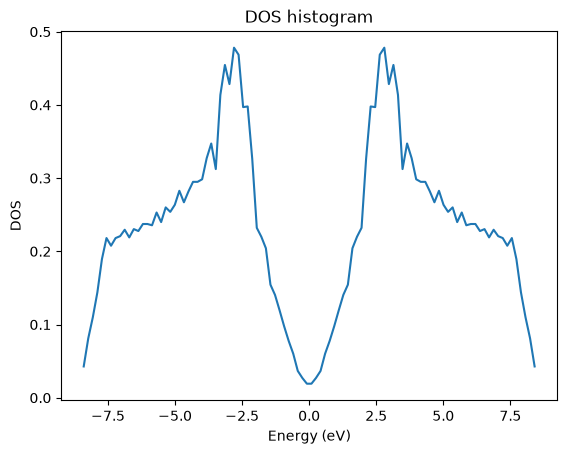

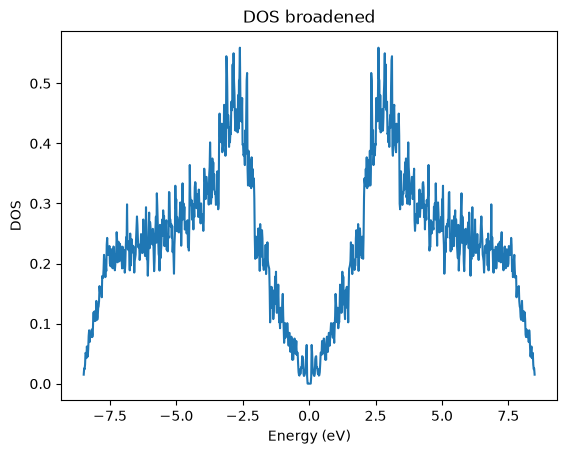

In [19]:

# I'm continuing task 4 here because the last cell takes forever to run, probably because the mesh is much finer than it needs to be. (Update, graphing in this
# cell was also taking forever because of the broadening, so I lowered the mesh size which made that cell and this cell run fast, but at this point, I'm not going
# to remerge them) In any case, I can plot energies on a histogram, and get the DOS by dividing the number of counts in each bin by the mesh size * difference 
# in energy between each bin. We confirm the normalization by summing the DOS * difference in energies and get 4, which is expected for our 4 bands when spin is 
# not counted. 

Nk = N**3

counts, edges = np.histogram(energies, bins = 100)

dE = edges[1] - edges[0]
centers = (edges[:-1] + edges[1:]) / 2

DOS = counts / (Nk * dE)

plt.plot(centers, DOS)
plt.xlabel("Energy (eV)")
plt.ylabel("DOS")
plt.title("DOS histogram")
plt.savefig("problem3_task4_graph1.png", dpi = 600)

print("DOS sum:", np.sum(DOS * dE))

# To broaden, every energy bin was turned into a thin gaussian with sigma 0.01 ev. It has the same general shape as the histogram, which is expected.

energies = np.asarray(energies).flatten()

sigma = 0.01

energy_x = np.linspace(energies.min(), energies.max(), 1000)

DOS = np.zeros_like(energy_x)

for i in energies:
    DOS += (np.exp(-(energy_x - i)**2 / (2 * sigma**2))) / (Nk * sigma * np.sqrt(2 * np.pi))


plt.figure()
plt.plot(energy_x, DOS)
plt.xlabel("Energy (eV)")
plt.ylabel("DOS")
plt.title("DOS broadened")
plt.savefig("problem3_task4_graph2.png", dpi = 600)

print("Broadening sigma:", sigma)

In [20]:
# task 5

# Calculating is easy enough since the parameters are all given. This value is notably larger than the empirical gamma1 value, and would not be great if used
# in calculations. Harrison's parameters are general, but the distances for every molecule are different. Perhaps the fact that graphite has a weak interlayer
# bond compared to "most" other materials throws off the Harrison estimate. 

h2_m = 7.62
d_perp = 3.35
Vpps = 2.22 * h2_m / d_perp**2

print("Vpps:", Vpps)

Vpps: 1.507364669191357


In [21]:
# task 6

# The fermi energy this model predicts is at 0 eV at the H point, implying graphite to be a metallic conductor. There are of course tons of unaccounted for
# interactions. For this problem, we ignored spin and the spin orbit coupling that would arise from that. Since this is a nearest neighbor approximation, 
# we also only factored in the layers directly above and below, and nothing further. 